## Setup and load data

In [ ]:
from pathlib import Path
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Update this path if your CSV is stored in a different folder.
DATA_PATH = Path(r"C:\TRAINING_CODES\Online_Food_Delivery_Analysis\CLEANED_ORDERS.csv")

if not DATA_PATH.exists():
    raise FileNotFoundError(
        f"Dataset not found: {DATA_PATH}\n"
        "Update DATA_PATH to the location of CLEANED_ORDERS.csv."
    )

df_raw = pd.read_csv(DATA_PATH)
df = df_raw.copy()

print(f"Rows: {df.shape[0]:,}")
print(f"Columns: {df.shape[1]:,}")
display(df.head())

Rows: 97,011
Columns: 25


,Order_ID,Customer_ID,Customer_Age,Customer_Gender,City,Area,Restaurant_ID,Restaurant_Name,Cuisine_Type,Order_Date,...,Final_Amount,Payment_Mode,Order_Status,Cancellation_Reason,Delivery_Partner_ID,Delivery_Rating,Restaurant_Rating,Order_Day,Peak_Hour,Profit_Margin
0,ORD000001,CUST6948,19.000000,Male,Unknown,Central,RES936,Restaurant_29,Chinese,2024-10-20,...,1147.0,UPI,Delivered,Not Cancelled,DP563,5.0,4.4,Weekend,True,0.13
1,ORD000002,CUST6515,38.976516,Female,Chennai,North,RES689,Restaurant_419,Chinese,2024-08-12,...,4849.0,COD,Delivered,Not Cancelled,DP369,5.0,4.7,Weekday,True,0.48
2,ORD000003,CUST1765,38.976516,Male,Delhi,Unknown,RES723,Restaurant_244,Arabian,2024-12-08,...,737.0,Wallet,Delivered,Not Cancelled,DP580,4.0,4.9,Weekend,True,0.08
3,ORD000004,CUST2744,38.976516,Male,Mumbai,Central,RES951,Restaurant_178,Chinese,2024-10-08,...,1147.0,UPI,Cancelled,Late Delivery,DP155,2.0,3.4,Weekday,NaN,0.04
4,ORD000005,CUST4389,57.000000,Female,Chennai,South,RES419,Restaurant_262,Chinese,2024-02-04,...,352.0,Card,Delivered,Not Cancelled,DP728,2.0,4.4,Weekend,False,0.12


## Dataset overview

In [52]:
print("Dataset dimensions:", df.shape)
print("\nColumn names:")
print(df.columns.tolist())

print("\nData types:")
display(df.dtypes.rename("data_type").to_frame())

print("\nNumeric summary:")
display(df.describe().T)

print("\nCategorical summary:")
display(df.describe(include="object").T)

Dataset dimensions: (97011, 25)

Column names:
['Order_ID', 'Customer_ID', 'Customer_Age', 'Customer_Gender', 'City', 'Area', 'Restaurant_ID', 'Restaurant_Name', 'Cuisine_Type', 'Order_Date', 'Order_Time', 'Delivery_Time_Min', 'Distance_km', 'Order_Value', 'Discount_Applied', 'Final_Amount', 'Payment_Mode', 'Order_Status', 'Cancellation_Reason', 'Delivery_Partner_ID', 'Delivery_Rating', 'Restaurant_Rating', 'Order_Day', 'Peak_Hour', 'Profit_Margin']

Data types:


,data_type
Order_ID,str
Customer_ID,str
Customer_Age,float64
Customer_Gender,str
City,str
Area,str
Restaurant_ID,str
Restaurant_Name,str
Cuisine_Type,str
Order_Date,str



Numeric summary:


,count,mean,std,min,25%,50%,75%,max
Customer_Age,97011.0,38.974010,8.740165,18.0,38.976516,38.976516,39.00,60.0
Delivery_Time_Min,97011.0,124.986651,74.235768,20.0,58.000000,120.000000,165.00,300.0
Distance_km,97011.0,14.277400,10.450337,1.0,7.760000,9.970000,21.12,40.0
Order_Value,97011.0,1786.216439,1335.109596,150.0,935.000000,1197.000000,2740.00,5000.0
Discount_Applied,97011.0,86.027368,99.163006,0.0,20.000000,50.000000,100.00,300.0
Final_Amount,97011.0,1700.189071,1337.891853,0.0,846.000000,1147.000000,2651.50,5000.0
Delivery_Rating,81012.0,2.992149,1.414026,1.0,2.000000,3.000000,4.00,5.0
Restaurant_Rating,97011.0,4.199940,0.654189,3.0,3.600000,4.300000,4.90,5.0
Profit_Margin,97011.0,0.178816,0.166017,0.0,0.000000,0.150000,0.32,0.5



Categorical summary:


C:\Users\Harish\AppData\Local\Temp\ipykernel_11480\926941295.py:12: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  display(df.describe(include="object").T)


,count,unique,top,freq
Order_ID,97011,97011,ORD000001,1
Customer_ID,97011,8999,CUST2487,24
Customer_Gender,97011,4,Other,24381
City,97011,6,Hyderabad,16378
Area,97011,6,South,16228
Restaurant_ID,97011,900,RES591,143
Restaurant_Name,97011,500,Restaurant_450,238
Cuisine_Type,97011,6,Unknown,16344
Order_Date,97011,365,2024-07-15,319
Order_Time,97011,1,2026-11-12,97011


## Data-quality assessment

In [53]:
quality_summary = pd.DataFrame({
    "dtype": df.dtypes.astype(str),
    "missing_count": df.isna().sum(),
    "missing_pct": (df.isna().mean() * 100).round(2),
    "unique_non_null": df.nunique(dropna=True)
}).sort_values("missing_pct", ascending=False)

display(quality_summary)

print("Exact duplicate rows:", df.duplicated().sum())
print("\nRows containing at least one null:", df.isna().any(axis=1).sum())

,dtype,missing_count,missing_pct,unique_non_null
Peak_Hour,object,31944,32.93,2
Delivery_Rating,float64,15999,16.49,5
Customer_Age,float64,0,0.00,44
Customer_ID,str,0,0.00,8999
City,str,0,0.00,6
Area,str,0,0.00,6
Restaurant_ID,str,0,0.00,900
Customer_Gender,str,0,0.00,4
Order_ID,str,0,0.00,97011
Cuisine_Type,str,0,0.00,6


Exact duplicate rows: 0

Rows containing at least one null: 42540


In [54]:
# Count explicit placeholder labels in text columns.
text_cols = df.select_dtypes(include=["object", "string"]).columns
unknown_summary = []

for col in text_cols:
    values = df[col].astype("string").str.strip().str.lower()
    count = values.isin(["unknown", "unk", "n/a", "na"]).sum()
    if count:
        unknown_summary.append({
            "column": col,
            "placeholder_count": int(count),
            "placeholder_pct": round(count / len(df) * 100, 2)
        })

display(pd.DataFrame(unknown_summary))

,column,placeholder_count,placeholder_pct
0,Customer_Gender,24116,24.86
1,City,16205,16.70
2,Area,16179,16.68
3,Cuisine_Type,16344,16.85
4,Cancellation_Reason,5824,6.00


## Order status and overall order volume

,orders
Order_Status,
Delivered,82428
Cancelled,14583


,percentage
Order_Status,
Delivered,84.97
Cancelled,15.03


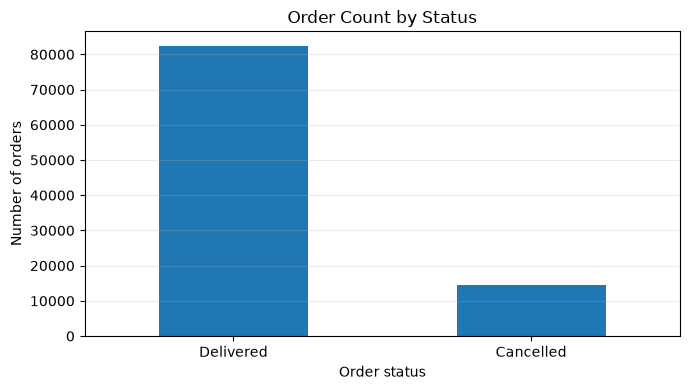

In [55]:
status_counts = df["Order_Status"].value_counts(dropna=False)
display(status_counts.rename("orders").to_frame())

status_pct = (df["Order_Status"].value_counts(normalize=True, dropna=False) * 100).round(2)
display(status_pct.rename("percentage").to_frame())

ax = status_counts.plot(kind="bar", figsize=(7, 4))
ax.set_title("Order Count by Status")
ax.set_xlabel("Order status")
ax.set_ylabel("Number of orders")
ax.grid(axis="y", alpha=0.25)
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

## Order value and delivered sales

In [56]:
for col in ["Order_Value", "Discount_Applied", "Final_Amount"]:
    if col in df.columns:
        print(f"\\n{col} summary")
        display(df[col].describe().to_frame().T)

delivered = df.loc[df["Order_Status"].eq("Delivered")].copy()
cancelled = df.loc[df["Order_Status"].eq("Cancelled")].copy()

print(f"Delivered orders: {len(delivered):,}")
print(f"Cancelled orders: {len(cancelled):,}")
print(f"Delivered Final_Amount total: ₹{delivered['Final_Amount'].sum():,.2f}")
print(f"Delivered average Final_Amount: ₹{delivered['Final_Amount'].mean():,.2f}")

\nOrder_Value summary


,count,mean,std,min,25%,50%,75%,max
Order_Value,97011.0,1786.216439,1335.109596,150.0,935.0,1197.0,2740.0,5000.0


\nDiscount_Applied summary


,count,mean,std,min,25%,50%,75%,max
Discount_Applied,97011.0,86.027368,99.163006,0.0,20.0,50.0,100.0,300.0


\nFinal_Amount summary


,count,mean,std,min,25%,50%,75%,max
Final_Amount,97011.0,1700.189071,1337.891853,0.0,846.0,1147.0,2651.5,5000.0


Delivered orders: 82,428
Cancelled orders: 14,583
Delivered Final_Amount total: ₹140,217,867.00
Delivered average Final_Amount: ₹1,701.10


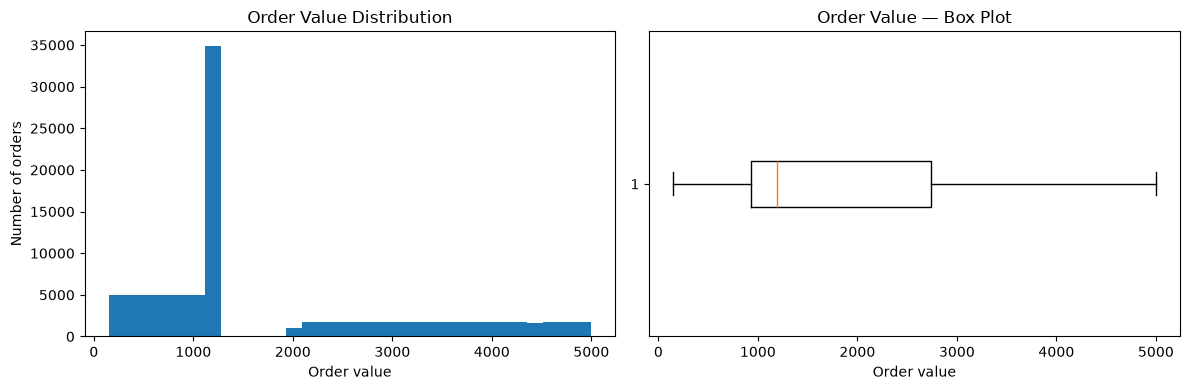

In [57]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].hist(df["Order_Value"].dropna(), bins=30)
axes[0].set_title("Order Value Distribution")
axes[0].set_xlabel("Order value")
axes[0].set_ylabel("Number of orders")

axes[1].boxplot(df["Order_Value"].dropna(), orientation="horizontal")
axes[1].set_title("Order Value — Box Plot")
axes[1].set_xlabel("Order value")

plt.tight_layout()
plt.show()

## Customer analysis

count    97011.000000
mean        38.974010
std          8.740165
min         18.000000
25%         38.976516
50%         38.976516
75%         39.000000
max         60.000000
Name: Customer_Age, dtype: float64

Most frequent age values:


,records
Customer_Age,
38.976516,48557
27.000000,1232
33.000000,1217
49.000000,1207
34.000000,1172
46.000000,1167
19.000000,1165
53.000000,1164
23.000000,1163


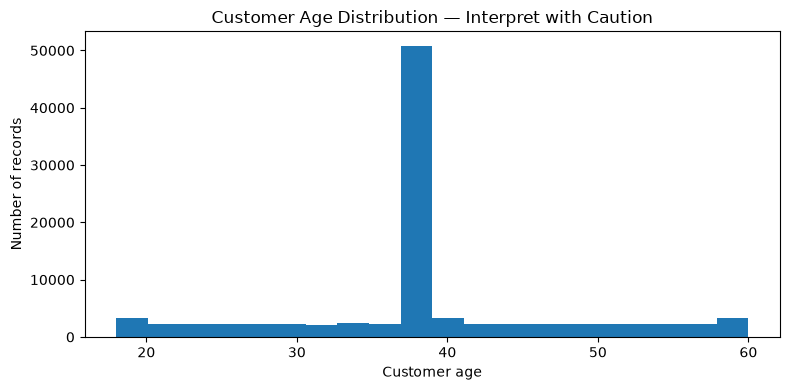

In [58]:
if "Customer_Age" in df.columns:
    age_summary = df["Customer_Age"].describe()
    print(age_summary)
    repeated_age = df["Customer_Age"].value_counts(dropna=False).head(10)
    print("\nMost frequent age values:")
    display(repeated_age.rename("records").to_frame())

    if df["Customer_Age"].notna().any():
        plt.figure(figsize=(8, 4))
        plt.hist(df["Customer_Age"].dropna(), bins=20)
        plt.title("Customer Age Distribution — Interpret with Caution")
        plt.xlabel("Customer age")
        plt.ylabel("Number of records")
        plt.tight_layout()
        plt.show()

In [59]:
if "Customer_Gender" in df.columns:
    gender_summary = (
        df.groupby("Customer_Gender", dropna=False)
          .agg(
              Orders=("Order_ID", "nunique"),
              Delivered_Orders=("Order_Status", lambda s: s.eq("Delivered").sum()),
              Mean_Order_Value=("Order_Value", "mean"),
              Mean_Final_Amount=("Final_Amount", "mean")
          )
          .sort_values("Orders", ascending=False)
    )
    display(gender_summary.round(2))

,Orders,Delivered_Orders,Mean_Order_Value,Mean_Final_Amount
Customer_Gender,,,,
Other,24381,20607,1789.50,1702.58
Female,24290,20734,1797.20,1711.90
Male,24224,20594,1783.39,1697.05
Unknown,24116,20493,1774.68,1689.13


## City, area and cuisine analysis

In [60]:
def category_summary(data, column):
    return (
        data.groupby(column, dropna=False)
            .agg(
                Orders=("Order_ID", "nunique"),
                Delivered_Orders=("Order_Status", lambda s: s.eq("Delivered").sum()),
                Delivered_Amount=("Final_Amount", lambda s: s[data.loc[s.index, "Order_Status"].eq("Delivered")].sum()),
                Mean_Order_Value=("Order_Value", "mean")
            )
            .sort_values("Orders", ascending=False)
    )

for col in ["City", "Area", "Cuisine_Type"]:
    if col in df.columns:
        print(f"\\n{col} summary")
        display(category_summary(df, col).round(2))

\nCity summary


,Orders,Delivered_Orders,Delivered_Amount,Mean_Order_Value
City,,,,
Hyderabad,16378,13900,23487169.0,1777.37
Bangalore,16236,13817,23684616.0,1798.36
Delhi,16212,13766,23337509.0,1778.44
Unknown,16205,13770,23441256.0,1788.60
Mumbai,15991,13596,23097254.0,1782.24
Chennai,15989,13579,23170063.0,1792.39


\nArea summary


,Orders,Delivered_Orders,Delivered_Amount,Mean_Order_Value
Area,,,,
South,16228,13761,23323498.0,1783.66
North,16198,13724,23388766.0,1785.82
Unknown,16179,13757,23436946.0,1785.25
East,16149,13749,23261228.0,1775.87
West,16147,13746,23419070.0,1791.38
Central,16110,13691,23388359.0,1795.36


\nCuisine_Type summary


,Orders,Delivered_Orders,Delivered_Amount,Mean_Order_Value
Cuisine_Type,,,,
Unknown,16344,13898,23789147.0,1795.59
Indian,16203,13697,23327079.0,1793.69
Chinese,16171,13774,23559799.0,1789.86
Arabian,16146,13768,23117492.0,1769.13
Mexican,16111,13666,23426680.0,1792.05
Italian,16036,13625,22997670.0,1776.79


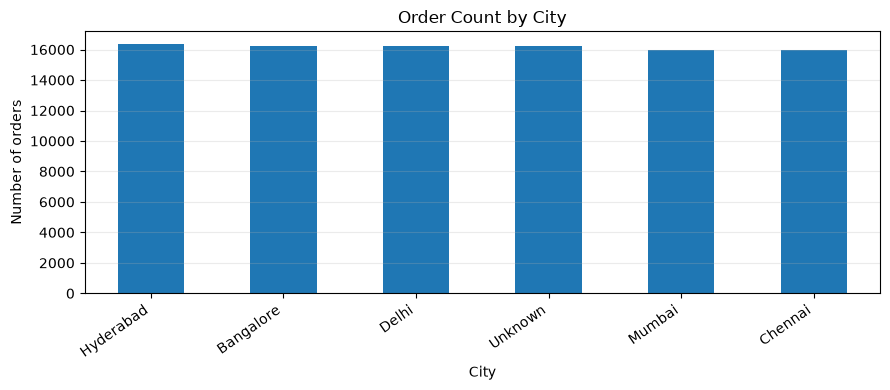

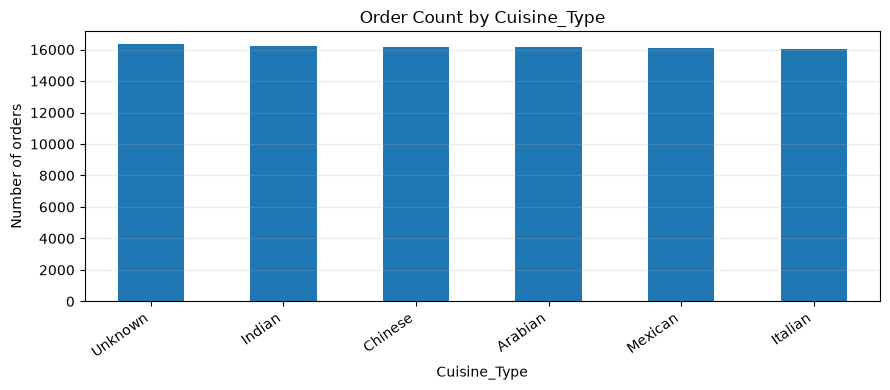

In [61]:
for col in ["City", "Cuisine_Type"]:
    if col in df.columns:
        counts = df[col].fillna("Missing").value_counts(dropna=False)
        plt.figure(figsize=(9, 4))
        counts.plot(kind="bar")
        plt.title(f"Order Count by {col}")
        plt.xlabel(col)
        plt.ylabel("Number of orders")
        plt.xticks(rotation=35, ha="right")
        plt.grid(axis="y", alpha=0.25)
        plt.tight_layout()
        plt.show()

## Date and weekday/weekend analysis

In [62]:
df["Order_Date_Parsed"] = pd.to_datetime(df["Order_Date"], errors="coerce")

print("Unparseable Order_Date values:", df["Order_Date_Parsed"].isna().sum())
print("Date range:", df["Order_Date_Parsed"].min(), "to", df["Order_Date_Parsed"].max())
print("Unique valid dates:", df["Order_Date_Parsed"].nunique())

if "Order_Day" in df.columns:
    day_summary = (
        df.groupby("Order_Day", dropna=False)
          .agg(
              Orders=("Order_ID", "nunique"),
              Active_Days=("Order_Date_Parsed", "nunique")
          )
    )
    day_summary["Average_Orders_Per_Active_Day"] = (
        day_summary["Orders"] / day_summary["Active_Days"].replace(0, np.nan)
    )
    display(day_summary.round(2))

Unparseable Order_Date values: 0
Date range: 2024-01-01 00:00:00 to 2024-12-30 00:00:00
Unique valid dates: 365


,Orders,Active_Days,Average_Orders_Per_Active_Day
Order_Day,,,
Weekday,69216,261,265.20
Weekend,27795,104,267.26


In [63]:
if "Order_Day" in df.columns:
    delivered_day = (
        delivered.groupby("Order_Day", dropna=False)
                 .agg(
                     Delivered_Orders=("Order_ID", "nunique"),
                     Delivered_Amount=("Final_Amount", "sum"),
                     Average_Final_Amount=("Final_Amount", "mean")
                 )
    )
    display(delivered_day.round(2))

,Delivered_Orders,Delivered_Amount,Average_Final_Amount
Order_Day,,,
Weekday,58813,100230023.0,1704.22
Weekend,23615,39987844.0,1693.32


## Delivery operations

In [64]:
delivery_cols = ["Delivery_Time_Min", "Distance_km", "Delivery_Rating", "Restaurant_Rating"]
display(df[[c for c in delivery_cols if c in df.columns]].describe().T)

print("Most frequent delivery times:")
display(df["Delivery_Time_Min"].value_counts().head(10).rename("records").to_frame())

print("Records with delivery time exactly 120 minutes:",
      int(df["Delivery_Time_Min"].eq(120).sum()))
print("Share at exactly 120 minutes:",
      round(df["Delivery_Time_Min"].eq(120).mean() * 100, 2), "%")

print("Most frequent distances:")
display(df["Distance_km"].value_counts().head(10).rename("records").to_frame())

,count,mean,std,min,25%,50%,75%,max
Delivery_Time_Min,97011.0,124.986651,74.235768,20.0,58.00,120.00,165.00,300.0
Distance_km,97011.0,14.277400,10.450337,1.0,7.76,9.97,21.12,40.0
Delivery_Rating,81012.0,2.992149,1.414026,1.0,2.00,3.00,4.00,5.0
Restaurant_Rating,97011.0,4.199940,0.654189,3.0,3.60,4.30,4.90,5.0


Most frequent delivery times:


,records
Delivery_Time_Min,
120.0,32520
64.0,686
36.0,684
42.0,683
27.0,665
26.0,665
38.0,661
24.0,660
67.0,657


Records with delivery time exactly 120 minutes: 32520
Share at exactly 120 minutes: 33.52 %
Most frequent distances:


,records
Distance_km,
9.97,32488
1.97,58
4.68,52
7.85,52
1.24,52
9.86,51
5.61,51
1.07,51
5.62,51


Delivered orders available for distance/time analysis: 82,428
Pearson correlation: 0.0053
Spearman correlation: 0.0051


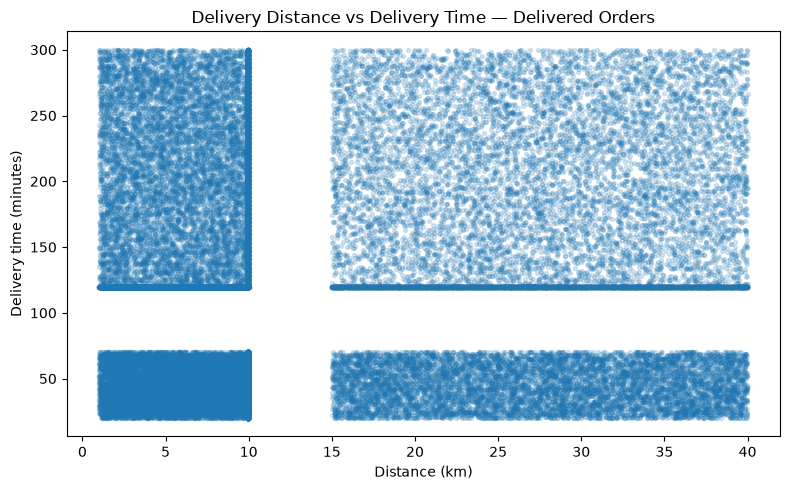

In [65]:
# Use delivered orders for delivery-time and distance analysis.
delivery_order_level = delivered.dropna(
    subset=["Delivery_Time_Min", "Distance_km"]
).copy()

print("Delivered orders available for distance/time analysis:",
      f"{len(delivery_order_level):,}")

pearson = delivery_order_level[["Distance_km", "Delivery_Time_Min"]].corr(method="pearson").iloc[0, 1]
spearman = delivery_order_level[["Distance_km", "Delivery_Time_Min"]].corr(method="spearman").iloc[0, 1]

print(f"Pearson correlation: {pearson:.4f}")
print(f"Spearman correlation: {spearman:.4f}")

plt.figure(figsize=(8, 5))
plt.scatter(
    delivery_order_level["Distance_km"],
    delivery_order_level["Delivery_Time_Min"],
    alpha=0.18,
    s=8
)
plt.title("Delivery Distance vs Delivery Time — Delivered Orders")
plt.xlabel("Distance (km)")
plt.ylabel("Delivery time (minutes)")
plt.tight_layout()
plt.show()

## Delivery ratings

In [66]:
rating_availability = (
    df.groupby("Order_Status", dropna=False)["Delivery_Rating"]
      .agg(
          Rating_Records="count",
          Missing_Ratings=lambda s: s.isna().sum(),
          Total_Orders="size"
      )
)
rating_availability["Rating_Completion_Pct"] = (
    rating_availability["Rating_Records"] /
    rating_availability["Total_Orders"] * 100
)
display(rating_availability.round(2))

rating_time_summary = (
    df.groupby("Delivery_Rating", dropna=True)["Delivery_Time_Min"]
      .agg(["count", "mean", "median", "std"])
      .round(2)
)
display(rating_time_summary)

rating_corr = df[["Delivery_Time_Min", "Delivery_Rating"]].corr(method="pearson").iloc[0, 1]
rating_rank_corr = df[["Delivery_Time_Min", "Delivery_Rating"]].corr(method="spearman").iloc[0, 1]
print(f"Pearson correlation (delivery time vs delivery rating): {rating_corr:.4f}")
print(f"Spearman correlation (delivery time vs delivery rating): {rating_rank_corr:.4f}")

,Rating_Records,Missing_Ratings,Total_Orders,Rating_Completion_Pct
Order_Status,,,,
Cancelled,12186,2397,14583,83.56
Delivered,68826,13602,82428,83.50


,count,mean,median,std
Delivery_Rating,,,,
1.0,16303,124.94,120.0,73.91
2.0,16420,124.83,120.0,74.34
3.0,15880,124.39,120.0,73.81
4.0,16428,125.65,120.0,74.06
5.0,15981,125.58,120.0,74.67


Pearson correlation (delivery time vs delivery rating): 0.0040
Spearman correlation (delivery time vs delivery rating): 0.0033


## Delivery partner analysis — exploratory only

In [67]:
partner_total = (
    df.groupby("Delivery_Partner_ID", dropna=False)
      .agg(Total_Orders=("Order_ID", "nunique"))
)

partner_status = (
    df.assign(
        Is_Delivered=df["Order_Status"].eq("Delivered"),
        Is_Cancelled=df["Order_Status"].eq("Cancelled")
    )
    .groupby("Delivery_Partner_ID", dropna=False)
    .agg(
        Delivered_Orders=("Is_Delivered", "sum"),
        Cancelled_Orders=("Is_Cancelled", "sum")
    )
)

partner_delivered = (
    delivered.groupby("Delivery_Partner_ID", dropna=False)
             .agg(
                 Average_Delivery_Time=("Delivery_Time_Min", "mean"),
                 Average_Distance=("Distance_km", "mean")
             )
)

partner_ratings = (
    df.groupby("Delivery_Partner_ID", dropna=False)["Delivery_Rating"]
      .agg(Average_Rating="mean", Rating_Count="count")
)

partner_summary = partner_total.join(partner_status).join(partner_delivered).join(partner_ratings)
partner_summary["Delivery_Rate_Pct"] = (
    partner_summary["Delivered_Orders"] / partner_summary["Total_Orders"] * 100
)
partner_summary["Cancellation_Rate_Pct"] = (
    partner_summary["Cancelled_Orders"] / partner_summary["Total_Orders"] * 100
)

display(partner_summary.sort_values("Total_Orders", ascending=False).head(15).round(2))

,Total_Orders,Delivered_Orders,Cancelled_Orders,Average_Delivery_Time,Average_Distance,Average_Rating,Rating_Count,Delivery_Rate_Pct,Cancellation_Rate_Pct
Delivery_Partner_ID,,,,,,,,,
DP543,139,117,22,131.08,13.53,2.93,122,84.17,15.83
DP458,139,120,19,125.62,14.00,3.04,121,86.33,13.67
DP121,137,106,31,119.34,14.00,3.00,105,77.37,22.63
DP485,136,104,32,133.92,14.88,2.84,112,76.47,23.53
DP783,136,110,26,123.49,14.81,3.08,113,80.88,19.12
DP474,135,108,27,127.46,14.52,3.02,119,80.00,20.00
DP653,134,116,18,126.29,12.48,3.15,109,86.57,13.43
DP100,134,115,19,114.68,14.84,3.02,117,85.82,14.18
DP148,133,107,26,124.37,13.03,2.99,116,80.45,19.55


In [68]:
# Only show rate comparisons for partners with at least 30 orders.
MIN_ORDERS = 30
eligible_partners = partner_summary.loc[partner_summary["Total_Orders"] >= MIN_ORDERS]

print("Partners meeting minimum order threshold:", len(eligible_partners))
print("\nHighest observed delivery rates:")
display(eligible_partners.nlargest(10, "Delivery_Rate_Pct")[
    ["Total_Orders", "Delivered_Orders", "Delivery_Rate_Pct", "Cancellation_Rate_Pct"]
].round(2))

print("\nLowest observed delivery rates:")
display(eligible_partners.nsmallest(10, "Delivery_Rate_Pct")[
    ["Total_Orders", "Delivered_Orders", "Delivery_Rate_Pct", "Cancellation_Rate_Pct"]
].round(2))

Partners meeting minimum order threshold: 900

Highest observed delivery rates:


,Total_Orders,Delivered_Orders,Delivery_Rate_Pct,Cancellation_Rate_Pct
Delivery_Partner_ID,,,,
DP664,98,93,94.90,5.10
DP688,106,100,94.34,5.66
DP361,104,98,94.23,5.77
DP674,102,96,94.12,5.88
DP264,116,109,93.97,6.03
DP785,96,90,93.75,6.25
DP960,95,89,93.68,6.32
DP523,109,102,93.58,6.42
DP759,108,101,93.52,6.48



Lowest observed delivery rates:


,Total_Orders,Delivered_Orders,Delivery_Rate_Pct,Cancellation_Rate_Pct
Delivery_Partner_ID,,,,
DP422,98,72,73.47,26.53
DP610,80,60,75.00,25.00
DP462,109,82,75.23,24.77
DP943,97,73,75.26,24.74
DP634,111,84,75.68,24.32
DP192,104,79,75.96,24.04
DP924,105,80,76.19,23.81
DP108,101,77,76.24,23.76
DP727,93,71,76.34,23.66


## Restaurant identity validation — data-quality finding

In [69]:
restaurant_id_to_names = df.groupby("Restaurant_ID")["Restaurant_Name"].nunique(dropna=True)
restaurant_name_to_ids = df.groupby("Restaurant_Name")["Restaurant_ID"].nunique(dropna=True)
order_to_restaurant_ids = df.groupby("Order_ID")["Restaurant_ID"].nunique(dropna=True)
order_to_restaurant_names = df.groupby("Order_ID")["Restaurant_Name"].nunique(dropna=True)

print("Unique restaurant IDs:", df["Restaurant_ID"].nunique())
print("Unique restaurant names:", df["Restaurant_Name"].nunique())
print("Restaurant IDs associated with multiple names:",
      int((restaurant_id_to_names > 1).sum()))
print("Restaurant names associated with multiple IDs:",
      int((restaurant_name_to_ids > 1).sum()))
print("Orders associated with multiple restaurant IDs:",
      int((order_to_restaurant_ids > 1).sum()))
print("Orders associated with multiple restaurant names:",
      int((order_to_restaurant_names > 1).sum()))

Unique restaurant IDs: 900
Unique restaurant names: 500
Restaurant IDs associated with multiple names: 900
Restaurant names associated with multiple IDs: 500
Orders associated with multiple restaurant IDs: 0
Orders associated with multiple restaurant names: 0


## Date/time field validation and peak-hour exclusion

In [70]:
print("Order_Date dtype:", df["Order_Date"].dtype)
print("Order_Time dtype:", df["Order_Time"].dtype)
print("Unique Order_Date values:", df["Order_Date"].nunique(dropna=True))
print("Unique Order_Time values:", df["Order_Time"].nunique(dropna=True))

print("\nOrder_Time sample values:")
display(df["Order_Time"].value_counts(dropna=False).head(10).to_frame("records"))

print("\nPeak_Hour distribution:")
display(df["Peak_Hour"].value_counts(dropna=False).to_frame("records"))

print("\nPeak_Hour vs Order_Time:")
display(pd.crosstab(df["Peak_Hour"], df["Order_Time"], dropna=False))

Order_Date dtype: str
Order_Time dtype: str
Unique Order_Date values: 365
Unique Order_Time values: 1

Order_Time sample values:


,records
Order_Time,
2026-11-12,97011



Peak_Hour distribution:


,records
Peak_Hour,
False,32573
True,32494
NaN,31944



Peak_Hour vs Order_Time:


Order_Time,2026-11-12
Peak_Hour,
True,32494
NaN,31944
False,32573
